# Assignment 3 - Insurance Risk Prediction Models
## Notebook 2: Classification (High-risk vs Low-risk customers)

**Course:** Data Science Advanced Programming (IBM)
**Dataset:** `med-insurance.csv`

**Business question:** Which customers are *high risk*, i.e. likely to generate very large claims? Low-risk customers can be approved automatically; high-risk ones are routed to a human underwriter.

**Label definition (stated assumption):** the dataset has no ready-made risk label, so a customer is **High Risk (1)** if their yearly `expenses` fall in the **top 10 %** of all customers, otherwise Low Risk (0). This creates a realistic **imbalanced** problem (about 10 % positives). `expenses` is then **removed from the features** to avoid target leakage.

## 1. Setup, label creation and class balance

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier
import shap

warnings.filterwarnings('ignore')
SEED = 42
sns.set_theme(style='whitegrid', context='notebook')
FIG = 'figs/'

df = pd.read_csv('med-insurance.csv').drop_duplicates().reset_index(drop=True)
threshold = df['expenses'].quantile(0.90)
df['high_risk'] = (df['expenses'] >= threshold).astype(int)
print(f'High-risk threshold (90th percentile of expenses): ${threshold:,.0f}')
print(df['high_risk'].value_counts().rename({0: 'Low risk', 1: 'High risk'}))
print('High-risk share: {:.1%}'.format(df['high_risk'].mean()))
print('Accuracy of a useless "always predict low risk" model: {:.1%}'.format(1 - df['high_risk'].mean()))

High-risk threshold (90th percentile of expenses): $34,833
high_risk
Low risk     1203
High risk     134
Name: count, dtype: int64
High-risk share: 10.0%
Accuracy of a useless "always predict low risk" model: 90.0%


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


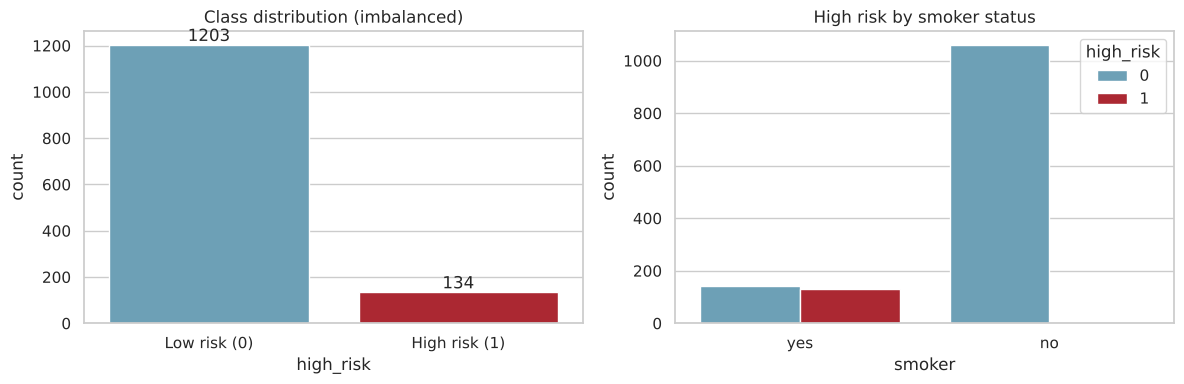

            age   bmi  children
high_risk                      
0          38.9  30.1       1.1
1          41.8  35.7       1.2
high_risk      0      1
smoker                 
no         0.997  0.003
yes        0.522  0.478


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='high_risk', ax=ax[0], palette=['#61a5c2', '#c1121f'])
ax[0].set_xticklabels(['Low risk (0)', 'High risk (1)']); ax[0].set_title('Class distribution (imbalanced)')
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
sns.countplot(data=df, x='smoker', hue='high_risk', ax=ax[1], palette=['#61a5c2', '#c1121f'])
ax[1].set_title('High risk by smoker status'); ax[1].legend(title='high_risk')
plt.tight_layout(); plt.savefig(FIG + 'clf_class_balance.png', dpi=160); plt.show()
print(df.groupby('high_risk')[['age', 'bmi', 'children']].mean().round(1))
print(pd.crosstab(df['smoker'], df['high_risk'], normalize='index').round(3))

## 2. Train / test split and preprocessing
Stratified 80 / 20 split on the label so the test set keeps the same ~10 % high-risk share. Resampling (SMOTE) is **only ever applied to training data inside cross-validation folds** - the test set is never touched by it.

In [3]:
X = df.drop(columns=['expenses', 'high_risk'])
y = df['high_risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print('Train positives:', y_train.sum(), '/', len(y_train), ' | Test positives:', y_test.sum(), '/', len(y_test))

num_cols, cat_cols = ['age', 'bmi', 'children'], ['sex', 'smoker', 'region']
def make_pre(scale):
    return ColumnTransformer([('num', StandardScaler() if scale else 'passthrough', num_cols),
                              ('cat', OneHotEncoder(drop='first'), cat_cols)])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print('scale_pos_weight for XGBoost = negatives/positives = {:.2f}'.format(pos_weight))

Train positives: 107 / 1069  | Test positives: 27 / 268
scale_pos_weight for XGBoost = negatives/positives = 8.99


## 3. Models and imbalance strategies
Four models x four strategies:

| Strategy | Idea |
|---|---|
| **None (baseline)** | Train on the imbalanced data as is |
| **Class weights** | Penalise mistakes on the minority class more (`class_weight='balanced'`, `scale_pos_weight` for XGBoost) |
| **SMOTE (oversampling)** | Create synthetic minority examples by interpolating between neighbouring high-risk customers |
| **Undersampling** | Randomly drop majority examples (loses information, shown for comparison) |

Every combination is cross-validated (5-fold, resampling inside each fold) and then scored once on the untouched test set.

In [4]:
def build(model_name, strategy):
    scale = model_name == 'Logistic Regression'
    pre = make_pre(scale)
    cw = 'balanced' if strategy == 'Class weights' else None
    if model_name == 'Logistic Regression':
        clf = LogisticRegression(max_iter=2000, class_weight=cw, random_state=SEED)
    elif model_name == 'Decision Tree':
        clf = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight=cw, random_state=SEED)
    elif model_name == 'Random Forest':
        clf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3, class_weight=cw, random_state=SEED, n_jobs=-1)
    else:
        clf = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=SEED, n_jobs=4,
                            eval_metric='logloss', scale_pos_weight=pos_weight if strategy == 'Class weights' else 1)
    steps = [('prep', pre)]
    if strategy == 'SMOTE': steps.append(('res', SMOTE(random_state=SEED, k_neighbors=5)))
    if strategy == 'Undersampling': steps.append(('res', RandomUnderSampler(random_state=SEED)))
    steps.append(('clf', clf))
    return Pipeline(steps)

models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']
strategies = ['None (baseline)', 'Class weights', 'SMOTE', 'Undersampling']
f2 = make_scorer(fbeta_score, beta=2)
scoring = {'recall': 'recall', 'precision': 'precision', 'roc_auc': 'roc_auc', 'f2': f2}

rows, fitted, probas = [], {}, {}
for m in models:
    for s in strategies:
        pipe = build(m, s)
        cvr = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        pipe.fit(X_train, y_train)
        p = pipe.predict_proba(X_test)[:, 1]
        pred = (p >= 0.5).astype(int)
        rows.append({'Model': m, 'Strategy': s,
                     'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0),
                     'Recall': recall_score(y_test, pred), 'F1': f1_score(y_test, pred), 'F2': fbeta_score(y_test, pred, beta=2),
                     'ROC_AUC': roc_auc_score(y_test, p),
                     'CV_Recall': cvr['test_recall'].mean(), 'CV_AUC': cvr['test_roc_auc'].mean(), 'CV_F2': cvr['test_f2'].mean()})
        fitted[(m, s)] = pipe; probas[(m, s)] = p
res = pd.DataFrame(rows)
res.to_csv('results/classification_comparison.csv', index=False)
display(res.round(3))

,Model,Strategy,Accuracy,Precision,Recall,F1,F2,ROC_AUC,CV_Recall,CV_AUC,CV_F2
0,Logistic Regression,None (baseline),0.985,0.960,0.889,0.923,0.902,0.991,0.831,0.986,0.851
1,Logistic Regression,Class weights,0.933,0.615,0.889,0.727,0.816,0.990,0.971,0.984,0.853
2,Logistic Regression,SMOTE,0.951,0.706,0.889,0.787,0.845,0.990,0.971,0.984,0.876
3,Logistic Regression,Undersampling,0.918,0.551,1.000,0.711,0.860,0.992,0.971,0.984,0.823
4,Decision Tree,None (baseline),0.981,1.000,0.815,0.898,0.846,0.940,0.887,0.974,0.900
5,Decision Tree,Class weights,0.963,0.774,0.889,0.828,0.863,0.942,0.953,0.974,0.922
6,Decision Tree,SMOTE,0.985,1.000,0.852,0.920,0.878,0.942,0.934,0.973,0.923
7,Decision Tree,Undersampling,0.981,0.923,0.889,0.906,0.896,0.982,0.944,0.976,0.935
8,Random Forest,None (baseline),0.985,1.000,0.852,0.920,0.878,0.991,0.888,0.987,0.898
9,Random Forest,Class weights,0.981,0.923,0.889,0.906,0.896,0.993,0.953,0.986,0.938


## 4. Why accuracy is misleading here
Compare accuracy with recall for the baseline models. A model can look excellent on accuracy while missing most high-risk customers.

,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.985,0.96,0.889,0.923,0.991
Decision Tree,0.981,1.00,0.815,0.898,0.940
Random Forest,0.985,1.00,0.852,0.920,0.991
XGBoost,0.989,1.00,0.889,0.941,0.968


A model that always predicts low risk has accuracy 89.9% but recall 0 %.


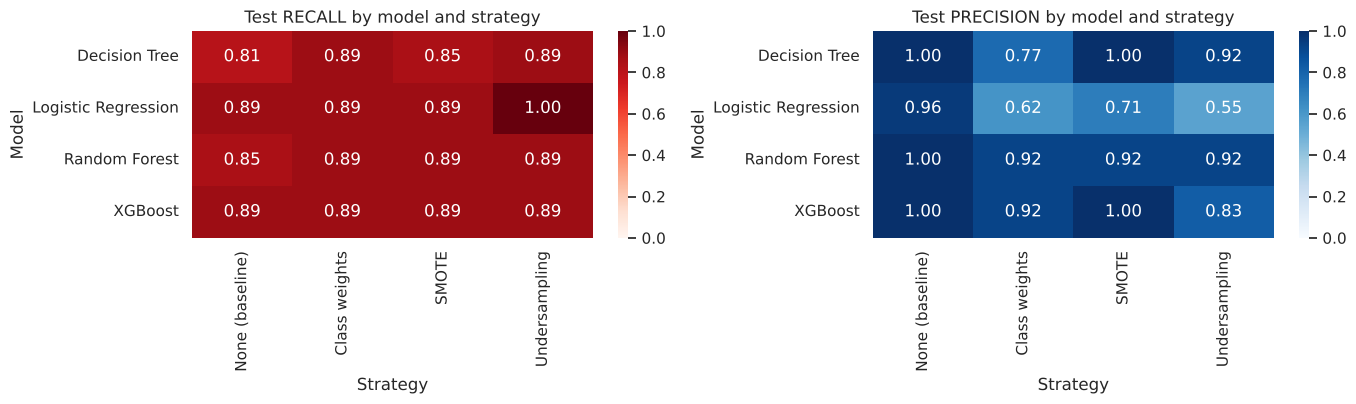

In [5]:
base = res[res['Strategy'] == 'None (baseline)'].set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']]
display(base.round(3))
naive_acc = 1 - y_test.mean()
print(f'A model that always predicts low risk has accuracy {naive_acc:.1%} but recall 0 %.')

piv = res.pivot(index='Model', columns='Strategy', values='Recall')[strategies]
piv2 = res.pivot(index='Model', columns='Strategy', values='Precision')[strategies]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(piv, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1, ax=ax[0]); ax[0].set_title('Test RECALL by model and strategy')
sns.heatmap(piv2, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax[1]); ax[1].set_title('Test PRECISION by model and strategy')
plt.tight_layout(); plt.savefig(FIG + 'clf_strategy_heatmaps.png', dpi=160); plt.show()

## 5. Selecting the best model
In insurance the cost of a **missed high-risk customer (false negative)** is much larger than the cost of an unnecessary manual review (false positive), so recall is weighted more than precision. We therefore select on the **cross-validated F2 score** (F-beta with beta = 2, recall counts twice as much as precision) - chosen on training folds only, so the test set stays unbiased.

Selected by CV F2: ('Random Forest', 'Class weights')


,Model,Strategy,CV_F2,CV_Recall,CV_AUC,Recall,Precision,F1,ROC_AUC
9,Random Forest,Class weights,0.938,0.953,0.986,0.889,0.923,0.906,0.993
7,Decision Tree,Undersampling,0.935,0.944,0.976,0.889,0.923,0.906,0.982
11,Random Forest,Undersampling,0.933,0.953,0.985,0.889,0.923,0.906,0.992
10,Random Forest,SMOTE,0.933,0.944,0.983,0.889,0.923,0.906,0.995
14,XGBoost,SMOTE,0.932,0.934,0.985,0.889,1.000,0.941,0.951


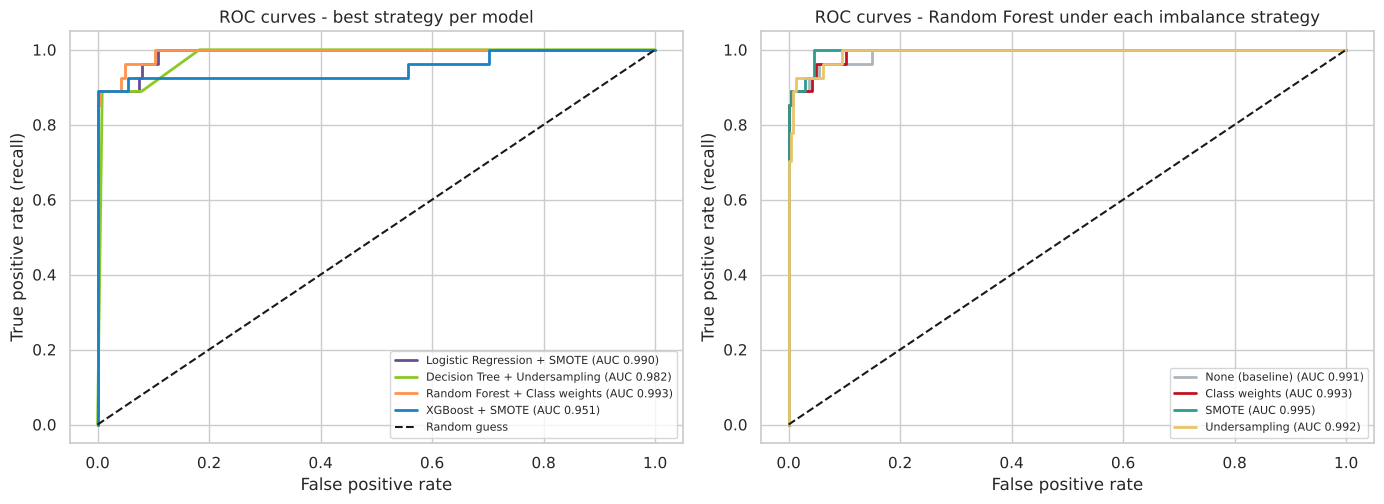

In [6]:
best_row = res.sort_values('CV_F2', ascending=False).iloc[0]
best_key = (best_row['Model'], best_row['Strategy'])
print('Selected by CV F2:', best_key)
display(res.sort_values('CV_F2', ascending=False).head(5)[['Model', 'Strategy', 'CV_F2', 'CV_Recall', 'CV_AUC', 'Recall', 'Precision', 'F1', 'ROC_AUC']].round(3))

# ROC curves: best strategy per model (by CV F2) + best overall
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
colors = {'Logistic Regression': '#6a4c93', 'Decision Tree': '#8ac926', 'Random Forest': '#ff924c', 'XGBoost': '#1982c4'}
for m in models:
    r = res[res['Model'] == m].sort_values('CV_F2', ascending=False).iloc[0]
    fpr, tpr, _ = roc_curve(y_test, probas[(m, r['Strategy'])])
    ax[0].plot(fpr, tpr, lw=2, color=colors[m], label=f"{m} + {r['Strategy']} (AUC {r['ROC_AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', label='Random guess'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate (recall)')
ax[0].set_title('ROC curves - best strategy per model'); ax[0].legend(loc='lower right', fontsize=8)
for s, c in zip(strategies, ['#adb5bd', '#c1121f', '#2a9d8f', '#e9c46a']):
    fpr, tpr, _ = roc_curve(y_test, probas[(best_key[0], s)])
    ax[1].plot(fpr, tpr, lw=2, color=c, label=f"{s} (AUC {roc_auc_score(y_test, probas[(best_key[0], s)]):.3f})")
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set_title(f'ROC curves - {best_key[0]} under each imbalance strategy'); ax[1].legend(loc='lower right', fontsize=8)
ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate (recall)')
plt.tight_layout(); plt.savefig(FIG + 'clf_roc.png', dpi=160); plt.show()

## 6. Confusion matrices

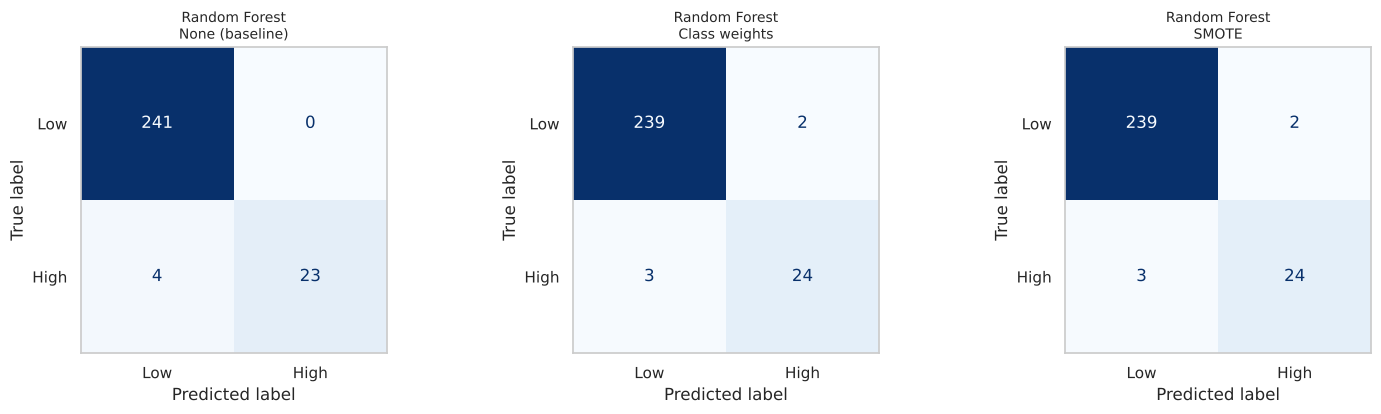

Best model ('Random Forest', 'Class weights'): TP=24 FN=3 FP=2 TN=239
Precision 0.923 | Recall 0.889 | Specificity 0.992


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
cases = [(best_key[0], 'None (baseline)'), best_key, ('Logistic Regression', 'None (baseline)')]
cases = [cases[0], cases[1]]
cases.append((best_key[0], 'SMOTE') if best_key[1] != 'SMOTE' else (best_key[0], 'Class weights'))
for a, k in zip(ax, cases):
    pred = (probas[k] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Low', 'High']).plot(ax=a, cmap='Blues', colorbar=False)
    a.set_title(f'{k[0]}\n{k[1]}', fontsize=10); a.grid(False)
plt.tight_layout(); plt.savefig(FIG + 'clf_confusion.png', dpi=160); plt.show()

bp = (probas[best_key] >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, bp).ravel()
print(f'Best model {best_key}: TP={tp} FN={fn} FP={fp} TN={tn}')
print(f'Precision {tp/(tp+fp):.3f} | Recall {tp/(tp+fn):.3f} | Specificity {tn/(tn+fp):.3f}')

## 7. Decision threshold: trading precision for recall
The default 0.5 cut-off is not sacred. The underwriting team can lower it to catch more high-risk customers at the cost of more manual reviews.

,threshold,precision,recall,flagged_for_review,missed_high_risk
0,0.2,0.650,0.963,40,1
1,0.3,0.828,0.889,29,3
2,0.4,0.923,0.889,26,3
3,0.5,0.923,0.889,26,3
4,0.6,0.960,0.889,25,3


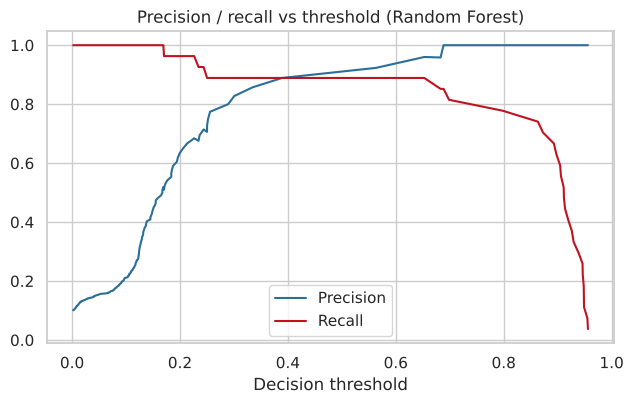

In [8]:
p = probas[best_key]
prec, rec, thr = precision_recall_curve(y_test, p)
rows_t = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pr = (p >= t).astype(int)
    rows_t.append({'threshold': t, 'precision': precision_score(y_test, pr, zero_division=0), 'recall': recall_score(y_test, pr),
                   'flagged_for_review': int(pr.sum()), 'missed_high_risk': int(((pr == 0) & (y_test == 1)).sum())})
tt = pd.DataFrame(rows_t); display(tt.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(thr, prec[:-1], label='Precision', color='#2a6f97'); ax.plot(thr, rec[:-1], label='Recall', color='#c1121f')
ax.set_xlabel('Decision threshold'); ax.set_title(f'Precision / recall vs threshold ({best_key[0]})'); ax.legend()
plt.tight_layout(); plt.savefig(FIG + 'clf_threshold.png', dpi=160); plt.show()

## 8. Decision tree for interpretability
A small tree is easy to read, but note how few levels it needs - and why a single deep tree overfits.

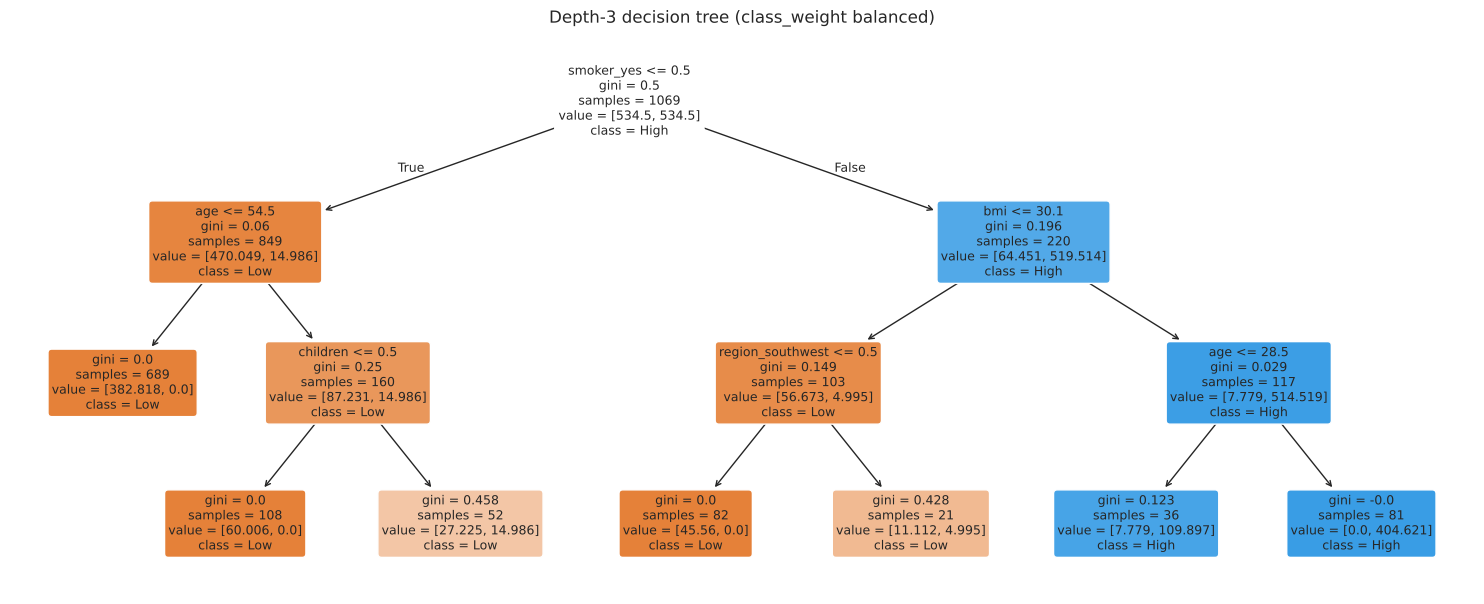

Unrestricted tree  - train AUC 1.000, test AUC 0.920  (overfits)


In [9]:
dt = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15, class_weight='balanced', random_state=SEED)
pre_t = make_pre(False).fit(X_train)
dt.fit(pre_t.transform(X_train), y_train)
fn_ = [n.split('__')[1] for n in pre_t.get_feature_names_out()]
plt.figure(figsize=(15, 6.2))
plot_tree(dt, feature_names=fn_, class_names=['Low', 'High'], filled=True, rounded=True, fontsize=9)
plt.title('Depth-3 decision tree (class_weight balanced)'); plt.tight_layout(); plt.savefig(FIG + 'clf_tree.png', dpi=160); plt.show()
deep = DecisionTreeClassifier(random_state=SEED).fit(pre_t.transform(X_train), y_train)
print('Unrestricted tree  - train AUC {:.3f}, test AUC {:.3f}  (overfits)'.format(
    roc_auc_score(y_train, deep.predict_proba(pre_t.transform(X_train))[:, 1]), roc_auc_score(y_test, deep.predict_proba(pre_t.transform(X_test))[:, 1])))

## 9. SHAP explainability for the selected classifier (mandatory)

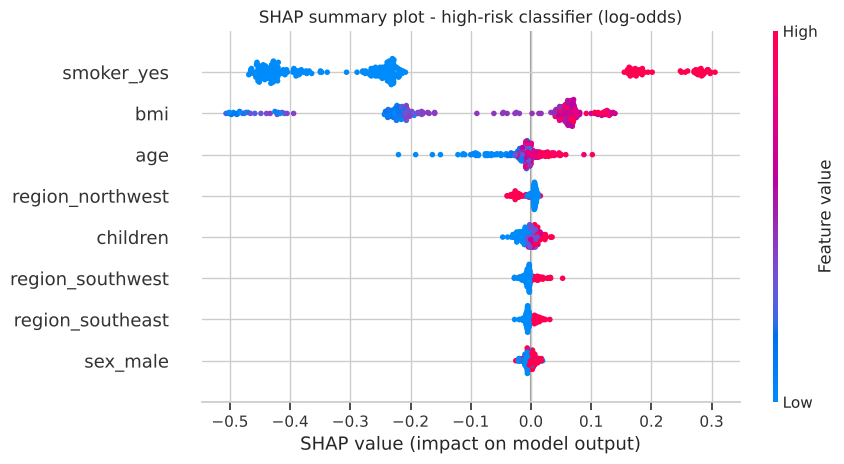

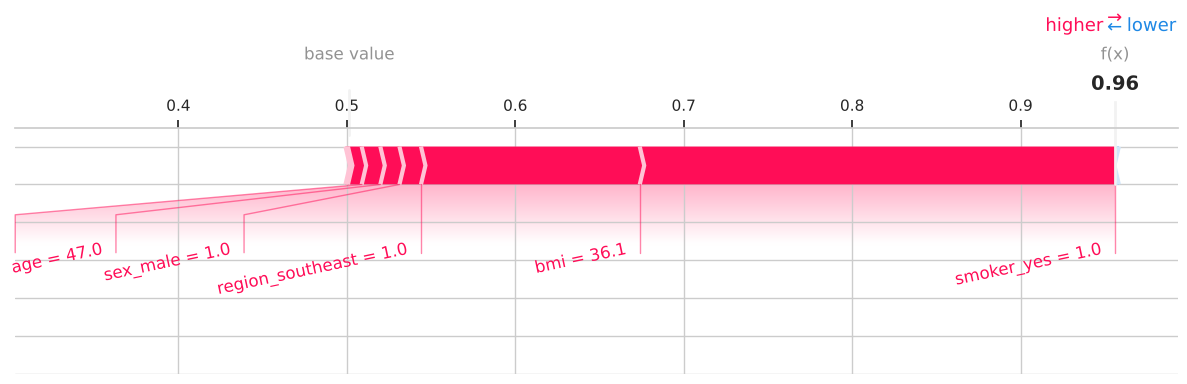

Customer explained: {'age': 47, 'sex': 'male', 'bmi': 36.1, 'children': 1, 'smoker': 'yes', 'region': 'southeast'} | P(high risk) = 0.956 | actual label: 1


,mean |SHAP|
smoker_yes,0.320
bmi,0.160
age,0.024
region_northwest,0.010
children,0.010
region_southwest,0.008
region_southeast,0.007
sex_male,0.006


In [10]:
pipe = fitted[best_key]
Xtr_t = pipe.named_steps['prep'].transform(X_train)
Xte_t = pipe.named_steps['prep'].transform(X_test)
fnames = [n.split('__')[1] for n in pipe.named_steps['prep'].get_feature_names_out()]
Xte_df = pd.DataFrame(Xte_t, columns=fnames)
mdl = pipe.named_steps['clf']
if isinstance(mdl, LogisticRegression):
    explainer = shap.LinearExplainer(mdl, pd.DataFrame(Xtr_t, columns=fnames))
else:
    explainer = shap.TreeExplainer(mdl)
sv = explainer(Xte_df)
vals = sv.values if sv.values.ndim == 2 else sv.values[:, :, 1]
base = sv.base_values if np.ndim(sv.base_values) == 1 else sv.base_values[:, 1]

plt.figure(); shap.summary_plot(vals, Xte_df, show=False, plot_size=(9, 4.8))
plt.title('SHAP summary plot - high-risk classifier (log-odds)'); plt.tight_layout()
plt.savefig(FIG + 'clf_shap_summary.png', dpi=160, bbox_inches='tight'); plt.show()

i = int(np.argmax(pipe.predict_proba(X_test)[:, 1]))
shap.force_plot(base[i], vals[i], Xte_df.iloc[i], matplotlib=True, show=False, figsize=(15, 3.2), text_rotation=12)
plt.savefig(FIG + 'clf_shap_force.png', dpi=160, bbox_inches='tight'); plt.show()
print('Customer explained:', X_test.iloc[i].to_dict(), '| P(high risk) =', round(float(pipe.predict_proba(X_test)[i, 1]), 3), '| actual label:', int(y_test.iloc[i]))
imp = pd.Series(np.abs(vals).mean(0), index=fnames).sort_values(ascending=False); display(imp.round(3).to_frame('mean |SHAP|'))

In [11]:
best_full = res[(res.Model == best_key[0]) & (res.Strategy == best_key[1])].iloc[0].to_dict()
out = {'threshold_usd': float(threshold), 'positive_rate': float(df['high_risk'].mean()),
       'n_train_pos': int(y_train.sum()), 'n_test_pos': int(y_test.sum()), 'n_test': int(len(y_test)),
       'naive_accuracy': float(naive_acc), 'pos_weight': float(pos_weight),
       'comparison': res.to_dict(orient='records'), 'best_key': list(best_key), 'best': best_full,
       'confusion': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)},
       'threshold_table': tt.to_dict(orient='records'),
       'shap_importance': imp.round(4).to_dict(),
       'force_customer': {'features': X_test.iloc[i].to_dict(), 'p_high': float(pipe.predict_proba(X_test)[i, 1]), 'actual': int(y_test.iloc[i])},
       'smoker_highrisk_rate': pd.crosstab(df['smoker'], df['high_risk'], normalize='index')[1].to_dict()}
json.dump(out, open('results/classification_results.json', 'w'), indent=2, default=float)
print('Saved results/classification_results.json')

Saved results/classification_results.json
